In [2]:
# Cell 1: Import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)
from imblearn.over_sampling import SMOTE

# Load the dataset (upload the CSV to Colab first)
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print("Shape:", df.shape)
df.head()

Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
# Cell 2: Initial data audit
print(df.info())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\n'N/A' strings in bmi:", (df['bmi'] == 'N/A').sum())
print("\nTarget distribution:")
print(df['stroke'].value_counts())
print("\nTarget distribution (%):")
print(df['stroke'].value_counts(normalize=True) * 100)
print("\nCategorical columns:")
for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(f"\n{col}:")
    print(df[col].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
None

Missing values per column:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0

In [4]:
# Cell 3: Data cleaning
# 3.1 Replace 'N/A' in bmi with NaN and convert to numeric
df['bmi'] = pd.to_numeric(df['bmi'].replace('N/A', np.nan), errors='coerce')

# 3.2 Impute missing bmi with the median (robust to outliers)
bmi_median = df['bmi'].median()
df['bmi'] = df['bmi'].fillna(bmi_median)
print("BMI median used for imputation:", bmi_median)
print("Remaining missing values:", df.isnull().sum().sum())

# 3.3 Drop the non-predictive identifier
df = df.drop(columns=['id'])

# 3.4 Remove the single 'Other' gender row (insufficient for learning)
df = df[df['gender'] != 'Other']
print("Shape after cleaning:", df.shape)

BMI median used for imputation: 28.1
Remaining missing values: 0
Shape after cleaning: (5109, 11)


In [5]:
# Cell 4: Encoding and train/test split
# 4.1 One-hot encode nominal categorical variables
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print("Shape after encoding:", df_encoded.shape)
print("Columns:", list(df_encoded.columns))

# 4.2 Separate features and target
X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']

# 4.3 Stratified train/test split (preserves class ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train target ratio:\n", y_train.value_counts(normalize=True))
print("Test target ratio:\n", y_test.value_counts(normalize=True))

Shape after encoding: (5109, 16)
Columns: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']
Train shape: (4087, 15) Test shape: (1022, 15)
Train target ratio:
 stroke
0    0.951309
1    0.048691
Name: proportion, dtype: float64
Test target ratio:
 stroke
0    0.951076
1    0.048924
Name: proportion, dtype: float64


In [6]:
# Cell 5: Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled train mean (approx 0):", np.round(X_train_scaled.mean(), 4))
print("Scaled train std (approx 1):", np.round(X_train_scaled.std(), 4))

Scaled train mean (approx 0): 0.0
Scaled train std (approx 1): 1.0


Before SMOTE: {0: 3888, 1: 199}
After SMOTE: {0: 3888, 1: 3888}


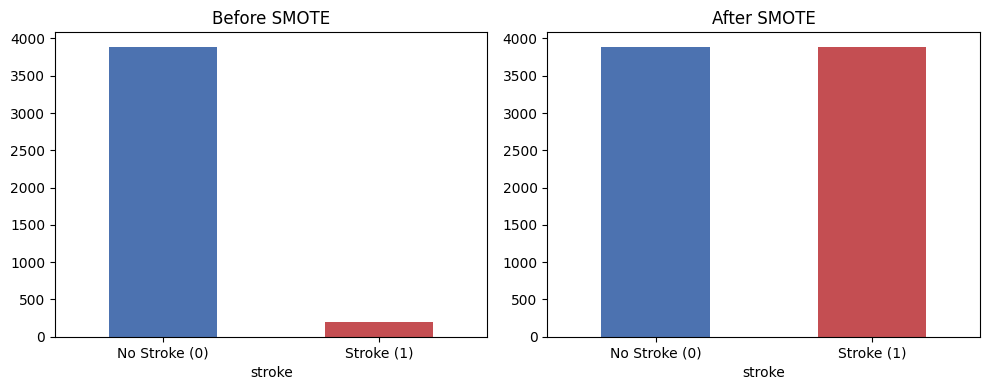

In [7]:
# Cell 6: Class imbalance before and after SMOTE (on training data only)
print("Before SMOTE:", y_train.value_counts().to_dict())

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)
print("After SMOTE:", pd.Series(y_train_res).value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pd.Series(y_train).value_counts().plot(kind='bar', ax=axes[0],
    title='Before SMOTE', color=['#4C72B0', '#C44E52'])
axes[0].set_xticklabels(['No Stroke (0)', 'Stroke (1)'], rotation=0)
pd.Series(y_train_res).value_counts().plot(kind='bar', ax=axes[1],
    title='After SMOTE', color=['#4C72B0', '#C44E52'])
axes[1].set_xticklabels(['No Stroke (0)', 'Stroke (1)'], rotation=0)
plt.tight_layout()
plt.savefig('smote_comparison.png', dpi=150)
plt.show()

In [8]:
# Cell 7: Baseline Logistic Regression (no class weighting, no SMOTE)
baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train_scaled, y_train)

y_pred_base = baseline.predict(X_test_scaled)
y_prob_base = baseline.predict_proba(X_test_scaled)[:, 1]

def evaluate(name, y_true, y_pred, y_prob):
    print(f"--- {name} ---")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1       :", round(f1_score(y_true, y_pred, zero_division=0), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_true, y_prob), 4))
    print()

evaluate("Baseline Logistic Regression", y_test, y_pred_base, y_prob_base)
print(classification_report(y_test, y_pred_base, zero_division=0))

--- Baseline Logistic Regression ---
Accuracy : 0.9521
Precision: 1.0
Recall   : 0.02
F1       : 0.0392
ROC-AUC  : 0.8394

              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



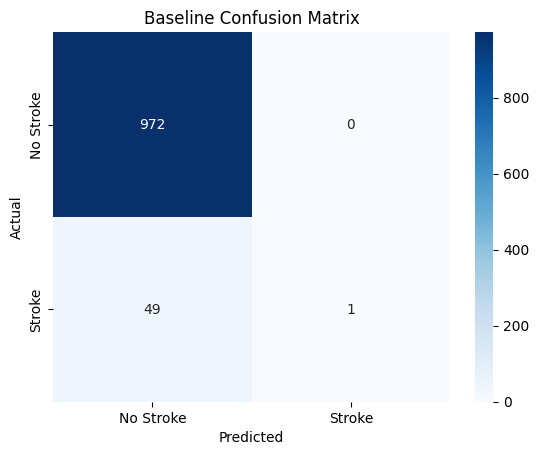

In [9]:
# Cell 8: Baseline confusion matrix
cm = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Stroke', 'Stroke'],
            yticklabels=['No Stroke', 'Stroke'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Baseline Confusion Matrix')
plt.savefig('baseline_cm.png', dpi=150)
plt.show()

In [10]:
# Cell 9: Refinement 1 — class_weight='balanced'
model_cw = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_cw.fit(X_train_scaled, y_train)
y_pred_cw = model_cw.predict(X_test_scaled)
y_prob_cw = model_cw.predict_proba(X_test_scaled)[:, 1]
evaluate("Class-Weighted Logistic Regression", y_test, y_pred_cw, y_prob_cw)

--- Class-Weighted Logistic Regression ---
Accuracy : 0.7387
Precision: 0.1347
Recall   : 0.8
F1       : 0.2305
ROC-AUC  : 0.8395



In [11]:
# Cell 10: Refinement 2 — SMOTE oversampling (training set only)
model_smote = LogisticRegression(max_iter=1000, random_state=42)
model_smote.fit(X_train_res, y_train_res)
y_pred_smote = model_smote.predict(X_test_scaled)
y_prob_smote = model_smote.predict_proba(X_test_scaled)[:, 1]
evaluate("SMOTE Logistic Regression", y_test, y_pred_smote, y_prob_smote)

--- SMOTE Logistic Regression ---
Accuracy : 0.7368
Precision: 0.1338
Recall   : 0.8
F1       : 0.2292
ROC-AUC  : 0.8406



In [13]:
# Cell 11: Refinement 3 — GridSearchCV on class-weighted model
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs'],
    'penalty': ['l2']
}
grid = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 4))

best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
y_prob_best = best_model.predict_proba(X_test_scaled)[:, 1]
evaluate("Tuned Class-Weighted Logistic Regression", y_test, y_pred_best, y_prob_best)
print(classification_report(y_test, y_pred_best, zero_division=0))

Best params: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV ROC-AUC: 0.8398
--- Tuned Class-Weighted Logistic Regression ---
Accuracy : 0.7299
Precision: 0.1307
Recall   : 0.8
F1       : 0.2247
ROC-AUC  : 0.8393

              precision    recall  f1-score   support

           0       0.99      0.73      0.84       972
           1       0.13      0.80      0.22        50

    accuracy                           0.73      1022
   macro avg       0.56      0.76      0.53      1022
weighted avg       0.94      0.73      0.81      1022



         Model  Accuracy  Precision  Recall     F1  ROC-AUC
      Baseline    0.9521     1.0000    0.02 0.0392   0.8394
Class-Weighted    0.7387     0.1347    0.80 0.2305   0.8395
         SMOTE    0.7368     0.1338    0.80 0.2292   0.8406
         Tuned    0.7299     0.1307    0.80 0.2247   0.8393


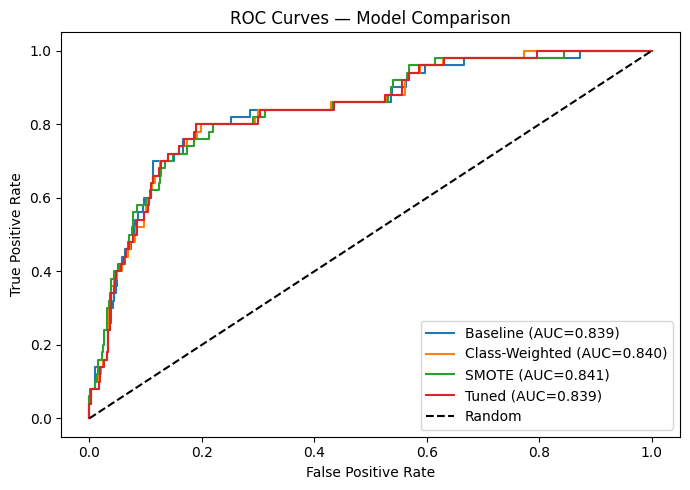

In [14]:
# Cell 12: Model comparison table and ROC curves
results = {
    'Baseline': (y_pred_base, y_prob_base),
    'Class-Weighted': (y_pred_cw, y_prob_cw),
    'SMOTE': (y_pred_smote, y_prob_smote),
    'Tuned': (y_pred_best, y_prob_best),
}
rows = []
for name, (yp, yprob) in results.items():
    rows.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, yp), 4),
        'Precision': round(precision_score(y_test, yp, zero_division=0), 4),
        'Recall': round(recall_score(y_test, yp, zero_division=0), 4),
        'F1': round(f1_score(y_test, yp, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_test, yprob), 4),
    })
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

plt.figure(figsize=(7, 5))
for name, (yp, yprob) in results.items():
    fpr, tpr, _ = roc_curve(y_test, yprob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, yprob):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Model Comparison')
plt.legend(); plt.tight_layout()
plt.savefig('roc_comparison.png', dpi=150)
plt.show()